# Reusing CPU assembly and check operators through the full CLN

This follow-up to [notebook 24](24_mexcuda_timing.ipynb) keeps all three stages, seven fields, local recovery limits and physical acceptance gates. Fixed-mesh NGSolve load and residual operators are assembled once **inside each complete run**, then reused through its stages. CPU and mexcuda recovery are compared with their unchanged bulk versions and both A-T references on the same idle NGSolve mdx GPU host.

See [the implementation and timing contract](CACHED_CLN.md). This route adds sparse validation/load storage, including a vector curl-curl **check** operator; it performs no global vector solve. The direct integrated curl error remains a quadrature calculation to avoid subtracting nearly equal energies.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
base=Path('data') if Path('data').is_dir() else Path('docs/data')
data=json.loads((base/'cached_cln_timing.json').read_text())
host=json.loads((base/'cached_cln_host.json').read_text())
controls=json.loads((base/'cached_cln_controls.json').read_text())
assert data['complete'] and host['complete'] and controls['complete']
routes=['original','condensed','scalar-bulk','scalar-cached','scalar-mexcuda','scalar-cached-mexcuda']
labels=['A-T','Condensed A-T','Bulk CPU','Cached CPU','Bulk mexcuda','Cached mexcuda']
def warm(c,route):return [r for r in c['repeats'] if r['route']==route and r['repeat']>0]
def median(c,route):return np.median([r['seconds'] for r in warm(c,route)])
print('Runtime:',data['runtime'])
print('Device:',data['matlab_engine']['device'])
print('Runs:',sum(len(c['repeats']) for c in data['cohorts']))
print('Foreign compute samples:',sum(bool(x) for x in host['foreign_compute_job_samples']))


Runtime: {'host': 'NGSolve', 'python': '3.12.10', 'ngsolve': '6.2.2607', 'numpy': '2.5.2', 'radia': '5.2.3', 'threads': 4, 'blas_pools': [{'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'libscipy_openblas', 'version': '0.3.34.0.0', 'threading_layer': 'pthreads', 'architecture': 'SkylakeX'}, {'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'openblas', 'version': '0.3.33', 'threading_layer': 'pthreads', 'architecture': 'Haswell'}, {'user_api': 'blas', 'internal_api': 'mkl', 'num_threads': 1, 'prefix': 'mkl_rt', 'version': '2026.1-Product', 'threading_layer': 'intel'}, {'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'libscipy_openblas', 'version': '0.3.31.dev', 'threading_layer': 'pthreads', 'architecture': 'SkylakeX'}, {'user_api': 'openmp', 'internal_api': 'openmp', 'num_threads': 18, 'prefix': 'libiomp', 'version': None}]}
Device: NVIDIA A100-SXM4-40GB
Runs: 96
Foreign compute samples: 0


## Full recursion: setup and every check included

The first observation and three warmed complete runs are retained for each route/cohort. Execution order reverses on alternating repeats. Every run rebuilds its scalar and recovery operators: this is not a prebuilt-operator-only latency. Mesh creation, imports, cross-route comparisons and saved reporting samples are excluded for every route. Engine launch is separate, as in notebook 24; its previous startup measurements are not repeated here.

| Cohort | A-T | Condensed A-T | Bulk CPU | Cached CPU | Bulk mexcuda | Cached mexcuda | CPU old/new | MEX old/new | Cached MEX/A-T |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| p=2, h=3 mm | 1.2644 | 1.2522 | 2.7266 | 2.4015 | 2.5925 | 2.2101 | 1.1354 | 1.1730 | 1.7480 |
| p=3, h=3 mm | 3.1784 | 2.2397 | 6.7954 | 5.8721 | 6.2415 | 5.1318 | 1.1572 | 1.2162 | 1.6146 |
| p=3, h=2 mm | 8.9604 | 6.6246 | 22.2654 | 18.4993 | 17.7523 | 14.2226 | 1.2036 | 1.2482 | 1.5873 |
| p=4, h=3 mm | 8.7081 | 4.9138 | 17.4107 | 15.7595 | 15.3634 | 13.7559 | 1.1048 | 1.1169 | 1.5797 |

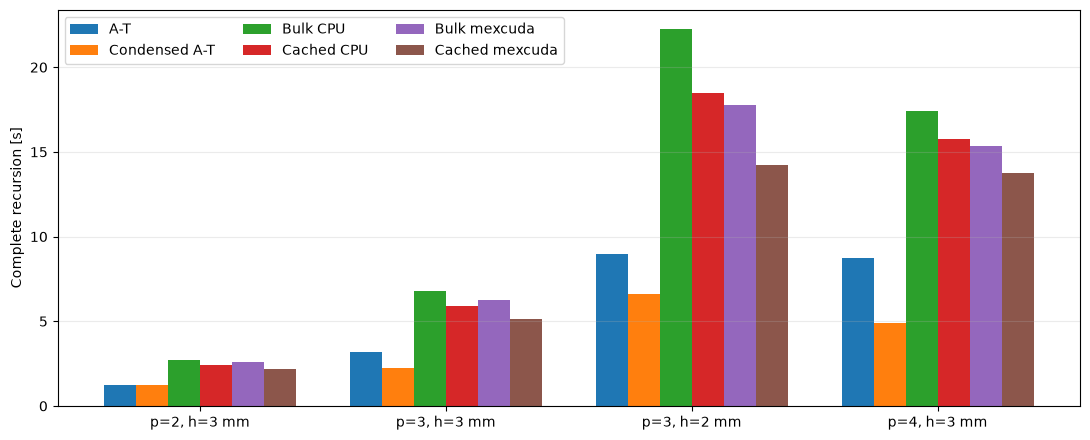

In [2]:
lines=['| Cohort | '+' | '.join(labels)+' | CPU old/new | MEX old/new | Cached MEX/A-T |','|---|'+'---:|'*9]
names=[];medians=[]
for c in data['cohorts']:
    name=f"p={c['order']}, h={1000*c['maxh']:g} mm"
    m=[median(c,r) for r in routes];names.append(name);medians.append(m)
    ratios=[m[2]/m[3],m[4]/m[5],m[5]/m[0]]
    lines.append('| '+name+' | '+' | '.join(f'{x:.4f}' for x in m+ratios)+' |')
display(Markdown('\n'.join(lines)))
fig,ax=plt.subplots(figsize=(11,4.5))
x=np.arange(len(names));width=.13
for i,label in enumerate(labels):ax.bar(x+(i-2.5)*width,np.array(medians)[:,i],width,label=label)
ax.set_xticks(x,names);ax.set_ylabel('Complete recursion [s]');ax.legend(ncol=3);ax.grid(axis='y',alpha=.25)
fig.tight_layout();plt.show()


In [3]:
lines=['| Cohort / route | First [s] | Warm min [s] | Warm median [s] | Warm max [s] |','|---|---:|---:|---:|---:|']
for c,name in zip(data['cohorts'],names):
    for route in routes:
        first=next(r['seconds'] for r in c['repeats'] if r['route']==route and r['repeat']==0)
        times=[r['seconds'] for r in warm(c,route)]
        lines.append(f"| {name} / {route} | {first:.4f} | {min(times):.4f} | {np.median(times):.4f} | {max(times):.4f} |")
display(Markdown('\n'.join(lines)))


| Cohort / route | First [s] | Warm min [s] | Warm median [s] | Warm max [s] |
|---|---:|---:|---:|---:|
| p=2, h=3 mm / original | 1.6319 | 1.1940 | 1.2644 | 1.3643 |
| p=2, h=3 mm / condensed | 0.8729 | 1.0409 | 1.2522 | 1.3015 |
| p=2, h=3 mm / scalar-bulk | 2.6741 | 2.6858 | 2.7266 | 2.8338 |
| p=2, h=3 mm / scalar-cached | 2.3498 | 2.3223 | 2.4015 | 2.4100 |
| p=2, h=3 mm / scalar-mexcuda | 2.6583 | 2.5636 | 2.5925 | 2.7621 |
| p=2, h=3 mm / scalar-cached-mexcuda | 2.1248 | 2.1971 | 2.2101 | 2.2112 |
| p=3, h=3 mm / original | 3.1274 | 3.1038 | 3.1784 | 3.5536 |
| p=3, h=3 mm / condensed | 2.2342 | 2.1970 | 2.2397 | 2.3268 |
| p=3, h=3 mm / scalar-bulk | 6.9175 | 6.7735 | 6.7954 | 6.9518 |
| p=3, h=3 mm / scalar-cached | 5.8268 | 5.8495 | 5.8721 | 5.9953 |
| p=3, h=3 mm / scalar-mexcuda | 6.2549 | 6.2167 | 6.2415 | 6.2901 |
| p=3, h=3 mm / scalar-cached-mexcuda | 5.1744 | 5.1291 | 5.1318 | 5.1974 |
| p=3, h=2 mm / original | 8.4838 | 8.3769 | 8.9604 | 9.2891 |
| p=3, h=2 mm / condensed | 6.3324 | 6.3217 | 6.6246 | 6.8778 |
| p=3, h=2 mm / scalar-bulk | 22.1410 | 21.9754 | 22.2654 | 22.3276 |
| p=3, h=2 mm / scalar-cached | 18.7148 | 18.3998 | 18.4993 | 18.7571 |
| p=3, h=2 mm / scalar-mexcuda | 17.7358 | 17.7050 | 17.7523 | 17.8799 |
| p=3, h=2 mm / scalar-cached-mexcuda | 14.3189 | 14.1863 | 14.2226 | 14.4713 |
| p=4, h=3 mm / original | 8.4857 | 8.4983 | 8.7081 | 8.7836 |
| p=4, h=3 mm / condensed | 4.8356 | 4.8015 | 4.9138 | 5.0578 |
| p=4, h=3 mm / scalar-bulk | 17.3996 | 17.2735 | 17.4107 | 17.4312 |
| p=4, h=3 mm / scalar-cached | 15.8635 | 15.6719 | 15.7595 | 15.8808 |
| p=4, h=3 mm / scalar-mexcuda | 15.3923 | 15.2198 | 15.3634 | 15.4396 |
| p=4, h=3 mm / scalar-cached-mexcuda | 14.0584 | 13.6947 | 13.7559 | 13.8264 |

## CPU phases and storage tradeoff

The following are medians of complete-run phase sums. Setup includes all cached-operator construction. Scalar/load/check, target assembly, physical residual checks and integrated field checks are nested in full recursion; these are not additional costs to add to the total. CSR bytes below are the logical arrays of the extra retained operators, not whole-process RAM or allocator peaks. Both T and A roles are counted. No general memory advantage is claimed.

In [4]:
keys=['scalar_seconds','target_seconds','physical_check_seconds','field_check_seconds']
lines=['| Cohort / route | Setup [s] | Scalar [s] | Targets [s] | Physical check [s] | Curl field check [s] | Cached CSR [MiB] |','|---|---:|---:|---:|---:|---:|---:|']
for c,name in zip(data['cohorts'],names):
    for route in routes[2:]:
        rows=warm(c,route)
        values=[np.median([r['setup_seconds'] for r in rows])]+[np.median([sum(s.get(k,0) for s in r['solves']) for r in rows]) for k in keys]
        memory=np.median([sum(r.get('cached_operator_csr_bytes_by_role',{}).values()) for r in rows])/2**20
        lines.append('| '+name+' / '+route+' | '+' | '.join(f'{v:.4f}' for v in values)+f' | {memory:.2f} |')
display(Markdown('\n'.join(lines)))


| Cohort / route | Setup [s] | Scalar [s] | Targets [s] | Physical check [s] | Curl field check [s] | Cached CSR [MiB] |
|---|---:|---:|---:|---:|---:|---:|
| p=2, h=3 mm / scalar-bulk | 0.8316 | 0.3949 | 0.1736 | 0.4423 | 0.2996 | 0.00 |
| p=2, h=3 mm / scalar-cached | 1.3127 | 0.0946 | 0.0076 | 0.0027 | 0.3922 | 27.69 |
| p=2, h=3 mm / scalar-mexcuda | 0.9322 | 0.3832 | 0.1743 | 0.4426 | 0.2796 | 0.00 |
| p=2, h=3 mm / scalar-cached-mexcuda | 1.3573 | 0.0942 | 0.0078 | 0.0026 | 0.3751 | 27.69 |
| p=3, h=3 mm / scalar-bulk | 2.1654 | 1.0517 | 0.4895 | 1.3143 | 0.4375 | 0.00 |
| p=3, h=3 mm / scalar-cached | 3.7575 | 0.2174 | 0.0189 | 0.0074 | 0.5421 | 136.82 |
| p=3, h=3 mm / scalar-mexcuda | 2.3782 | 1.0476 | 0.4911 | 1.3127 | 0.4199 | 0.00 |
| p=3, h=3 mm / scalar-cached-mexcuda | 3.7663 | 0.2168 | 0.0190 | 0.0072 | 0.5360 | 136.82 |
| p=3, h=2 mm / scalar-bulk | 6.3557 | 2.9883 | 1.4324 | 3.7964 | 0.9863 | 0.00 |
| p=3, h=2 mm / scalar-cached | 10.1884 | 0.6434 | 0.0484 | 0.0193 | 1.0938 | 404.33 |
| p=3, h=2 mm / scalar-mexcuda | 6.8683 | 2.9900 | 1.4390 | 3.7730 | 0.9931 | 0.00 |
| p=3, h=2 mm / scalar-cached-mexcuda | 10.7056 | 0.6366 | 0.0482 | 0.0191 | 1.0947 | 404.33 |
| p=4, h=3 mm / scalar-bulk | 6.2550 | 2.3035 | 1.1524 | 3.1104 | 0.6244 | 0.00 |
| p=4, h=3 mm / scalar-cached | 10.7008 | 0.4024 | 0.0536 | 0.0210 | 0.7170 | 476.69 |
| p=4, h=3 mm / scalar-mexcuda | 6.7645 | 2.3005 | 1.1552 | 3.0874 | 0.6132 | 0.00 |
| p=4, h=3 mm / scalar-cached-mexcuda | 11.1650 | 0.4015 | 0.0521 | 0.0209 | 0.7224 | 476.69 |

## Precision and independent checks

The matrix-based checks use the same quadrature as the archived LinearForms. NGSolve selects different default rules for linear and bilinear forms, so the rectangular load/check operators explicitly use `2 * test FE order + 8`; volume norm checks retain integration order 13. Native controls compare the original uncompiled load/check vectors on flat and curved meshes, orders 2–4, both boundary roles, changing scale and sign, and clearing previous/forcing buffers. Complete-run comparisons independently check coefficients, volume vector fields, sampled fields, original scalar equations and recovered original physical equations.

In [5]:
comparisons=[r for c in data['cohorts'] for r in c['comparisons'] if 'cached' in r['route']]
steps=[s for c in data['cohorts'] for r in c['repeats'] if 'cached' in r['route'] for s in r['solves']]
print('Maximum coefficient relative difference:',max(abs(x) for r in comparisons for x in r['relative_coefficients']))
print('Maximum volume-vector relative difference:',max(x for r in comparisons for x in r['volume_relative_field_errors']))
for key in ['scalar_trace_residual','original_scalar_residual','original_physical_residual','recovered_original_residual','relative_divergence','curl_fit_residual','relative_curl_field_error']:
    print(key,max(s[key] for s in steps))
print('Native control cases:',len(controls['cases']))
print('Maximum native vector difference:',max(max(r['physical_vector_relative_errors']+r['scalar_load_relative_errors']+[r['curl_load_relative_error'],r['scalar_operator_relative_error']]) for r in controls['cases']))
print('Global vector solves:',sorted(set(s['global_vector_solves'] for s in steps)))


Maximum coefficient relative difference: 1.2117218339824376e-10
Maximum volume-vector relative difference: 5.3496726138033356e-09
scalar_trace_residual 8.308410068656542e-14
original_scalar_residual 1.5103973425257617e-14
original_physical_residual 6.402548899015387e-11
recovered_original_residual 4.1997118881280565e-10
relative_divergence 1.547111894673373e-13
curl_fit_residual 9.760449566337615e-11
relative_curl_field_error 9.760652222581321e-11
Native control cases: 12
Maximum native vector difference: 6.656994017814012e-16
Global vector solves: [0]


Scope remains the constant-material, simply connected, zero-shift internal wire. This is same-mesh parity and host-specific timing, not an accuracy or speed theorem for other meshes, materials or stage counts. Runtime uses released Radia 5.2.3 plus hash-identified CLN sources and the unchanged MEX binary; no new package release is implied.

The separate C2 independent T–Omega validation, loss FEM convergence and F2/Radia API migration remain open. This CPU optimization does not close them.